<a href="https://colab.research.google.com/github/MarwaRayen/Capsule_Endoscopy_XAI_Project/blob/main/ZAHZAM_Marwa___Capsule_Endoscopy_XAI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable AI for Capsule Endoscopy

**Author:** Marwa Zahzam

**Question:** when a deep learning model classifies capsule endoscopy frames, can we trust
its explanations and its confidence?

This notebook is a small project to strengthen my application to the Explainable AI (xAI) for Capsule Endoscopy PhD Position and show my motivation and willingness to take on the work, the real purpose is to familiarize myself with Capsule Endoscopy images and apply my acquired knolewledge in explanations on this type of images as well as test some new cocepts such as calibration, color sensitivity tests...

the code below :
1. fine-tunes a pretrained CNN on the public **Kvasir-Capsule** dataset (using the offical official split),
2. generates explanations (Grad-CAM, Integrated Gradients, Saliency),
3. measures how **faithful** those explanations are (deletion / insertion tests),
4. measures how **calibrated** and **uncertain** the model is (ECE, temperature scaling, MC dropout),
5. studies how predictions and explanations react to **colour changes** (hue, saturation).

Dataset: Smedsrud et al., *Kvasir-Capsule, a video capsule endoscopy dataset*, Scientific Data, 2021.
https://datasets.simula.no/kvasir-capsule or https://osf.io/dv2ag

## 0. Setup

Runtime -> Change runtime type -> **GPU (T4)**.

Labelled images of Kvasir-Capsule are downloaded from the authors' public Google Drive folder straight onto Colab's own disk.
https://drive.google.com/drive/u/0/folders/18vEHN1CG7oNFKdT2NmhtJjrFhb3tLG1Z

Results are saved to the Drive.

In [ ]:
!pip -q install timm captum gdown

In [ ]:
import os, glob, zipfile, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image
import timm
from captum.attr import LayerGradCam, IntegratedGradients, Saliency, LayerAttribution
from sklearn.metrics import (balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import train_test_split

# ----------------------------- CONFIG -----------------------------
IN_COLAB = "google.colab" in str(globals().get("get_ipython", lambda: "")())
DRIVE_DIR = "/content/drive/MyDrive/kvasir_capsule"      # for result images
DATA_DIR = "/content/kvasir_data"
KVASIR_FOLDER_URL = "https://drive.google.com/drive/folders/1ZcIKXcQZf0UgC0mZ40muGHP-CAB__Fy6"   # Google drive folder for the labelled images
RESULTS_DIR = f"{DRIVE_DIR}/results"


MODEL_NAME = "resnet50"
IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 6
LR = 3e-4
NUM_WORKERS = 2
N_EXPLAIN = 200             # test images used for the faithfulness study
N_COLOUR = 400              # test images used for the colour study
MC_PASSES = 20              # forward passes for MC dropout
SEED = 42

FAST_DEV_RUN = False
# ------------------------------------------------------------------

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [ ]:
import gdown, tarfile

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(RESULTS_DIR, exist_ok=True)

has_images = os.path.isdir(DATA_DIR) and glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True)
if not has_images:
    os.makedirs(DATA_DIR, exist_ok=True)
    print("Downloading the labelled images folder...")
    archives = gdown.download_folder(url=KVASIR_FOLDER_URL, output=DATA_DIR, quiet=False)
    for path in archives:
        if path.endswith(".tar.gz"):
            print("Extracting", os.path.basename(path))
            with tarfile.open(path) as t:
                t.extractall(DATA_DIR)
            os.remove(path)
print("Data folder:", DATA_DIR)

Mounted at /content/drive


Retrieving folder contents


Processing file 1lGGzuXZtaN6Cu7JOkPz22DWXrd7gJyae ampulla_of_vater.tar.gz
Processing file 1qj7tyl-BWdI7QyPaa-CVkuYO8OlL7a05 angiectasia.tar.gz
Processing file 18NwrLgETVSln8xLJ3eH41_8wWrC-TwRf blood_fresh.tar.gz
Processing file 1fyU2LsuBDX5c8LIRtFjSEWGRjoYLbIKQ blood_hematin.tar.gz
Processing file 1b-SJYvzj3eELUN4FE2sgkzA7dO7-hSTz erosion.tar.gz
Processing file 1Rh8-ElJiDSuDSl0yRAuCmf4nlMxyIX8z erythema.tar.gz
Processing file 1QEMKV632XGGs9202iTyH-QggV_F3dSED foreign_body.tar.gz
Processing file 1DUZH9U1NPlobA9GAWWSbXvnFM2pnI4UE ileocecal_valve.tar.gz
Processing file 1ydBalZyqf1N9AMV6qPJgXtU1Ad-aAGDm lymphangiectasia.tar.gz
Processing file 1zJnmWpsCvYTbdo5ce2fYJuOCR1ykC4g7 normal_clean_mucosa.tar.gz
Processing file 1wTy_Wo1ErGgfvDXysbpIGfQeKMB6MgN- polyp.tar.gz
Processing file 1daW2cbk0EMcsDJRbVr4HRiYZpeMFxYUv pylorus.tar.gz
Processing file 1LVSm5o_xhJFPMIU3A-S1waBU7sKB_oQN reduced_mucosal_view.tar.gz
Processing file 1PIIIbWrgKPWz_9XA8PD86UsKLVnynQU1 ulcer.tar.gz


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lGGzuXZtaN6Cu7JOkPz22DWXrd7gJyae
To: /content/kvasir_data/ampulla_of_vater.tar.gz
100%|██████████| 103k/103k [00:00<00:00, 36.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1qj7tyl-BWdI7QyPaa-CVkuYO8OlL7a05
To: /content/kvasir_data/angiectasia.tar.gz
100%|██████████| 9.52M/9.52M [00:00<00:00, 45.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=18NwrLgETVSln8xLJ3eH41_8wWrC-TwRf
To: /content/kvasir_data/blood_fresh.tar.gz
100%|██████████| 5.27M/5.27M [00:00<00:00, 19.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1fyU2LsuBDX5c8LIRtFjSEWGRjoYLbIKQ
To: /content/kvasir_data/blood_hematin.tar.gz
100%|██████████| 138k/138k [00:00<00:00, 44.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1b-SJYvzj3eELUN4FE2sgkzA7dO7-hSTz
To: /content/kvasir_data/erosion.tar.gz
100%|██████████| 6.57M/6.57M [00:0

Extracting ampulla_of_vater.tar.gz
Extracting angiectasia.tar.gz
Extracting blood_fresh.tar.gz
Extracting blood_hematin.tar.gz
Extracting erosion.tar.gz
Extracting erythema.tar.gz
Extracting foreign_body.tar.gz
Extracting ileocecal_valve.tar.gz
Extracting lymphangiectasia.tar.gz
Extracting normal_clean_mucosa.tar.gz
Extracting polyp.tar.gz
Extracting pylorus.tar.gz
Extracting reduced_mucosal_view.tar.gz
Extracting ulcer.tar.gz
Data folder: /content/kvasir_data


## 1. Data

Using the **official splits** from the authors' GitHub repository: `split_0` for training and
`split_1` for testing. The two splits come from different videos, so the test set is a real
generalisation test which is nice.

In [ ]:
SPLIT_URL = "https://raw.githubusercontent.com/simula/kvasir-capsule/master/official_splits/split_{}.csv"
split0 = pd.read_csv(SPLIT_URL.format(0))
split1 = pd.read_csv(SPLIT_URL.format(1))

paths = {}
for ext in ("*.jpg", "*.png", "*.jpeg"):
    for p in glob.glob(os.path.join(DATA_DIR, "**", ext), recursive=True):
        paths[os.path.basename(p)] = p
print(f"Indexed {len(paths)} image files")

def attach_paths(df):
    df = df.copy()
    df["path"] = df["filename"].map(paths)
    missing = df["path"].isna().sum()
    if missing:
        print(f"Warning: {missing} files listed in the split were not found and are dropped")
    return df.dropna(subset=["path"]).reset_index(drop=True)

split0, split1 = attach_paths(split0), attach_paths(split1)

CLASSES = sorted(set(split0["label"]) | set(split1["label"]))
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, "classes:", CLASSES)

# Train and validation from split_0, test = split_1
train_df, val_df = train_test_split(split0, test_size=0.1, stratify=split0["label"], random_state=SEED)
test_df = split1

if FAST_DEV_RUN:
    train_df = train_df.groupby("label").head(8)
    val_df = val_df.groupby("label").head(4)
    test_df = test_df.groupby("label").head(4)
    EPOCHS, N_EXPLAIN, N_COLOUR, MC_PASSES = 1, 8, 8, 3

counts = pd.DataFrame({"train": train_df["label"].value_counts(),
                       "val": val_df["label"].value_counts(),
                       "test": test_df["label"].value_counts()}).fillna(0).astype(int)
counts.loc[CLASSES]

Indexed 47229 image files
11 classes: ['Angiectasia', 'Blood', 'Erosion', 'Erythematous', 'Foreign Bodies', 'Ileo-cecal valve', 'Lymphangiectasia', 'Normal', 'Pylorus', 'Reduced Mucosal View', 'Ulcer']


,train,val,test
label,,,
Angiectasia,694,77,95
Blood,20,2,424
Erosion,310,35,161
Erythematous,119,13,27
Foreign Bodies,531,59,186
Ileo-cecal valve,2515,280,1394
Lymphangiectasia,202,22,368
Normal,14267,1586,18485
Pylorus,844,94,591


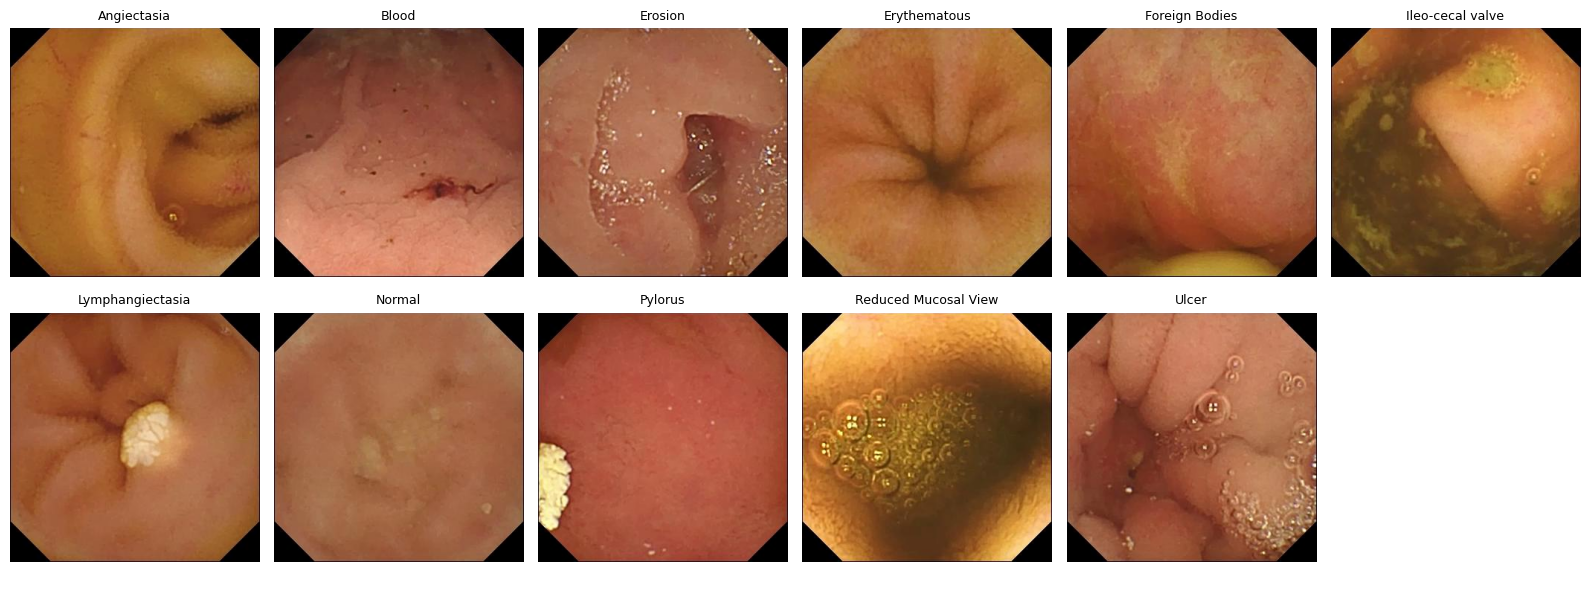

In [ ]:
# Few examples per class
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, cls in zip(axes.flat, CLASSES):
    p = train_df[train_df["label"] == cls]["path"].iloc[0]
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(cls, fontsize=9); ax.axis("off")
for ax in axes.flat[len(CLASSES):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/examples.png", dpi=120); plt.show()

In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics
normalize = T.Normalize(MEAN, STD)

train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
    T.ToTensor(), normalize])
# No colour augmentation on purpose: to study the model's colour sensitivity later.
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), normalize])
raw_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor()])   # un-normalised, for display / colour shifts

class CapsuleDataset(Dataset):
    def __init__(self, df, tf):
        self.paths, self.labels, self.tf = df["path"].tolist(), [CLS2IDX[l] for l in df["label"]], tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

train_ds, val_ds, test_ds = CapsuleDataset(train_df, train_tf), CapsuleDataset(val_df, eval_tf), CapsuleDataset(test_df, eval_tf)
train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
val_dl = DataLoader(val_ds, BATCH_SIZE, num_workers=NUM_WORKERS)
test_dl = DataLoader(test_ds, BATCH_SIZE, num_workers=NUM_WORKERS)

## 2. Baseline model

Pretrained ResNet-50 (ImageNet) and fine-tuned. The classes are heavily imbalanced
("Normal" is about 70% of the data), so the loss is **weighted** by inverse class frequency, and **balanced accuracy** and **macro-F1** are reported rather than plain accuracy.

`drop_rate=0.3` adds dropout before the classifier.

In [ ]:
model = timm.create_model(MODEL_NAME, pretrained=not FAST_DEV_RUN, num_classes=NUM_CLASSES, drop_rate=0.3).to(device)

freq = train_df["label"].value_counts().reindex(CLASSES).fillna(1).values
class_weights = torch.tensor(len(train_df) / (NUM_CLASSES * freq), dtype=torch.float32)
class_weights = class_weights.clamp(max=50).to(device)     # avoid exploding weights for tiny classes
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_dl))
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

@torch.no_grad()
def predict_logits(model, loader):
    model.eval(); all_logits, all_y = [], []
    for x, y in loader:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            all_logits.append(model(x.to(device)).float().cpu())
        all_y.append(y)
    return torch.cat(all_logits), torch.cat(all_y)

def scores(logits, y):
    pred = logits.argmax(1)
    return balanced_accuracy_score(y, pred), f1_score(y, pred, average="macro")

best_f1, history = -1, []
for epoch in range(EPOCHS):
    model.train(); t0 = time.time(); running = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item() * len(x)
    val_logits, val_y = predict_logits(model, val_dl)
    bacc, mf1 = scores(val_logits, val_y)
    history.append({"epoch": epoch + 1, "loss": running / len(train_ds), "val_bacc": bacc, "val_macro_f1": mf1})
    print(f"Epoch {epoch+1}/{EPOCHS} loss={running/len(train_ds):.3f} val_bacc={bacc:.3f} val_macroF1={mf1:.3f} ({time.time()-t0:.0f}s)")
    if mf1 > best_f1:
        best_f1 = mf1; torch.save(model.state_dict(), f"{RESULTS_DIR}/best_model.pt")

model.load_state_dict(torch.load(f"{RESULTS_DIR}/best_model.pt", map_location=device))
pd.DataFrame(history)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/6 loss=1.251 val_bacc=0.820 val_macroF1=0.663 (112s)
Epoch 2/6 loss=0.307 val_bacc=0.962 val_macroF1=0.839 (121s)
Epoch 3/6 loss=0.147 val_bacc=0.983 val_macroF1=0.893 (118s)
Epoch 4/6 loss=0.069 val_bacc=0.984 val_macroF1=0.913 (121s)
Epoch 5/6 loss=0.050 val_bacc=0.983 val_macroF1=0.922 (116s)
Epoch 6/6 loss=0.044 val_bacc=0.979 val_macroF1=0.917 (121s)


,epoch,loss,val_bacc,val_macro_f1
0,1,1.251467,0.819828,0.662584
1,2,0.307306,0.961718,0.839488
2,3,0.147326,0.983094,0.892854
3,4,0.069084,0.984410,0.912803
4,5,0.049635,0.982714,0.921840
5,6,0.044386,0.978784,0.916564


TEST  balanced accuracy = 0.266   macro-F1 = 0.190

                      precision    recall  f1-score   support

         Angiectasia       0.02      0.04      0.03        95
               Blood       0.12      0.00      0.00       424
             Erosion       0.01      0.09      0.02       161
        Erythematous       0.00      0.00      0.00        27
      Foreign Bodies       0.23      0.65      0.34       186
    Ileo-cecal valve       0.26      0.63      0.36      1394
    Lymphangiectasia       0.15      0.04      0.07       368
              Normal       0.93      0.78      0.85     18485
             Pylorus       0.23      0.63      0.34       591
Reduced Mucosal View       0.17      0.04      0.07      1787
               Ulcer       0.05      0.01      0.02       582

            accuracy                           0.66     24100
           macro avg       0.20      0.27      0.19     24100
        weighted avg       0.75      0.66      0.69     24100



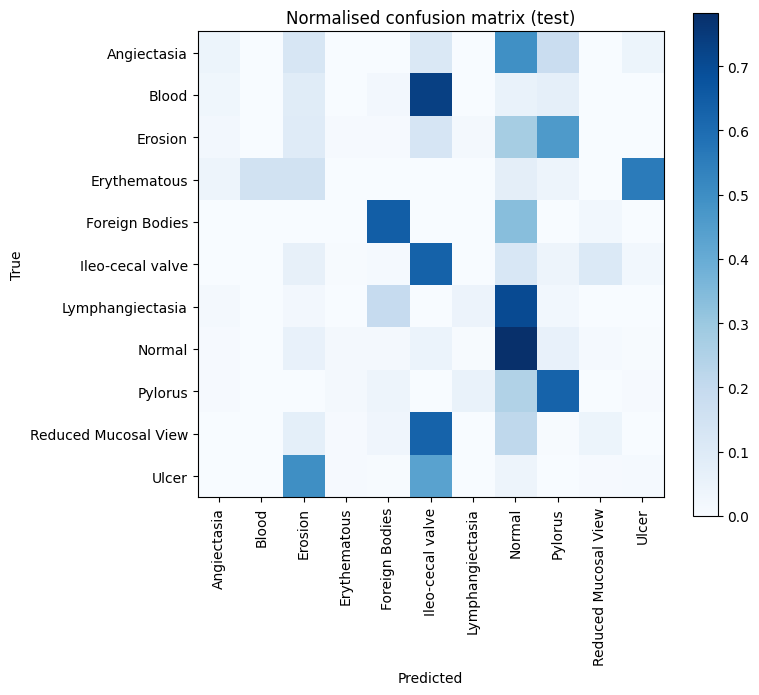

In [8]:
test_logits, test_y = predict_logits(model, test_dl)
test_pred = test_logits.argmax(1)
bacc, mf1 = scores(test_logits, test_y)
print(f"TEST  balanced accuracy = {bacc:.3f}   macro-F1 = {mf1:.3f}\n")
print(classification_report(test_y, test_pred, labels=range(NUM_CLASSES), target_names=CLASSES, zero_division=0))

cm = confusion_matrix(test_y, test_pred, labels=range(NUM_CLASSES), normalize="true")
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), CLASSES, rotation=90); plt.yticks(range(NUM_CLASSES), CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Normalised confusion matrix (test)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/confusion_matrix.png", dpi=120); plt.show()

## 3. Explanations and their faithfulness

Three attribution methods (Captum): **Grad-CAM** (last conv block), **Integrated Gradients**,
**Saliency** (plain gradients).

**Faithfulness test.** If an explanation really shows what the model uses, then:
- **Deletion:** progressively removing (blurring) the most important pixels should make the
  predicted-class probability drop **fast**; low area under the curve (AUC) is better.
- **Insertion:** starting from a blurred image and progressively restoring the most important
  pixels should make the probability rise **fast**; high AUC is better.

A **random** ranking is the baseline every method must beat.

In [9]:
model.eval()
target_layer = model.layer4 if hasattr(model, "layer4") else list(model.children())[-3]
gradcam = LayerGradCam(model, target_layer)
ig = IntegratedGradients(model)
saliency = Saliency(model)

def explain(method, x, target):
    """Returns a (H, W) non-negative importance map for one normalised image x of shape (1,3,H,W)."""
    x = x.clone().requires_grad_(True)
    if method == "Grad-CAM":
        a = gradcam.attribute(x, target=target)
        a = LayerAttribution.interpolate(a, x.shape[-2:], interpolate_mode="bilinear")
        a = F.relu(a)[0, 0]
    elif method == "Integrated Gradients":
        a = ig.attribute(x, baselines=torch.zeros_like(x), target=target, n_steps=32, internal_batch_size=16)
        a = a[0].abs().sum(0)
    elif method == "Saliency":
        a = saliency.attribute(x, target=target, abs=True)[0].sum(0)
    elif method == "Random":
        a = torch.rand(x.shape[-2:], device=x.device)
    return a.detach()

METHODS = ["Grad-CAM", "Integrated Gradients", "Saliency", "Random"]

# Pick test images from the clinically interesting (non-normal, non-landmark) classes
FINDINGS = [c for c in CLASSES if c not in ("Normal", "Ileo-cecal valve", "Pylorus", "Reduced Mucosal View", "Foreign Bodies")]
def sample_per_class(df, n_per_class):
    return pd.concat([g.sample(min(len(g), n_per_class), random_state=SEED) for _, g in df.groupby("label")])

explain_df = sample_per_class(test_df[test_df["label"].isin(FINDINGS)], max(1, N_EXPLAIN // len(FINDINGS)))
print(len(explain_df), "images for the explanation study:", explain_df["label"].value_counts().to_dict())

192 images for the explanation study: {'Angiectasia': 33, 'Blood': 33, 'Erosion': 33, 'Lymphangiectasia': 33, 'Ulcer': 33, 'Erythematous': 27}


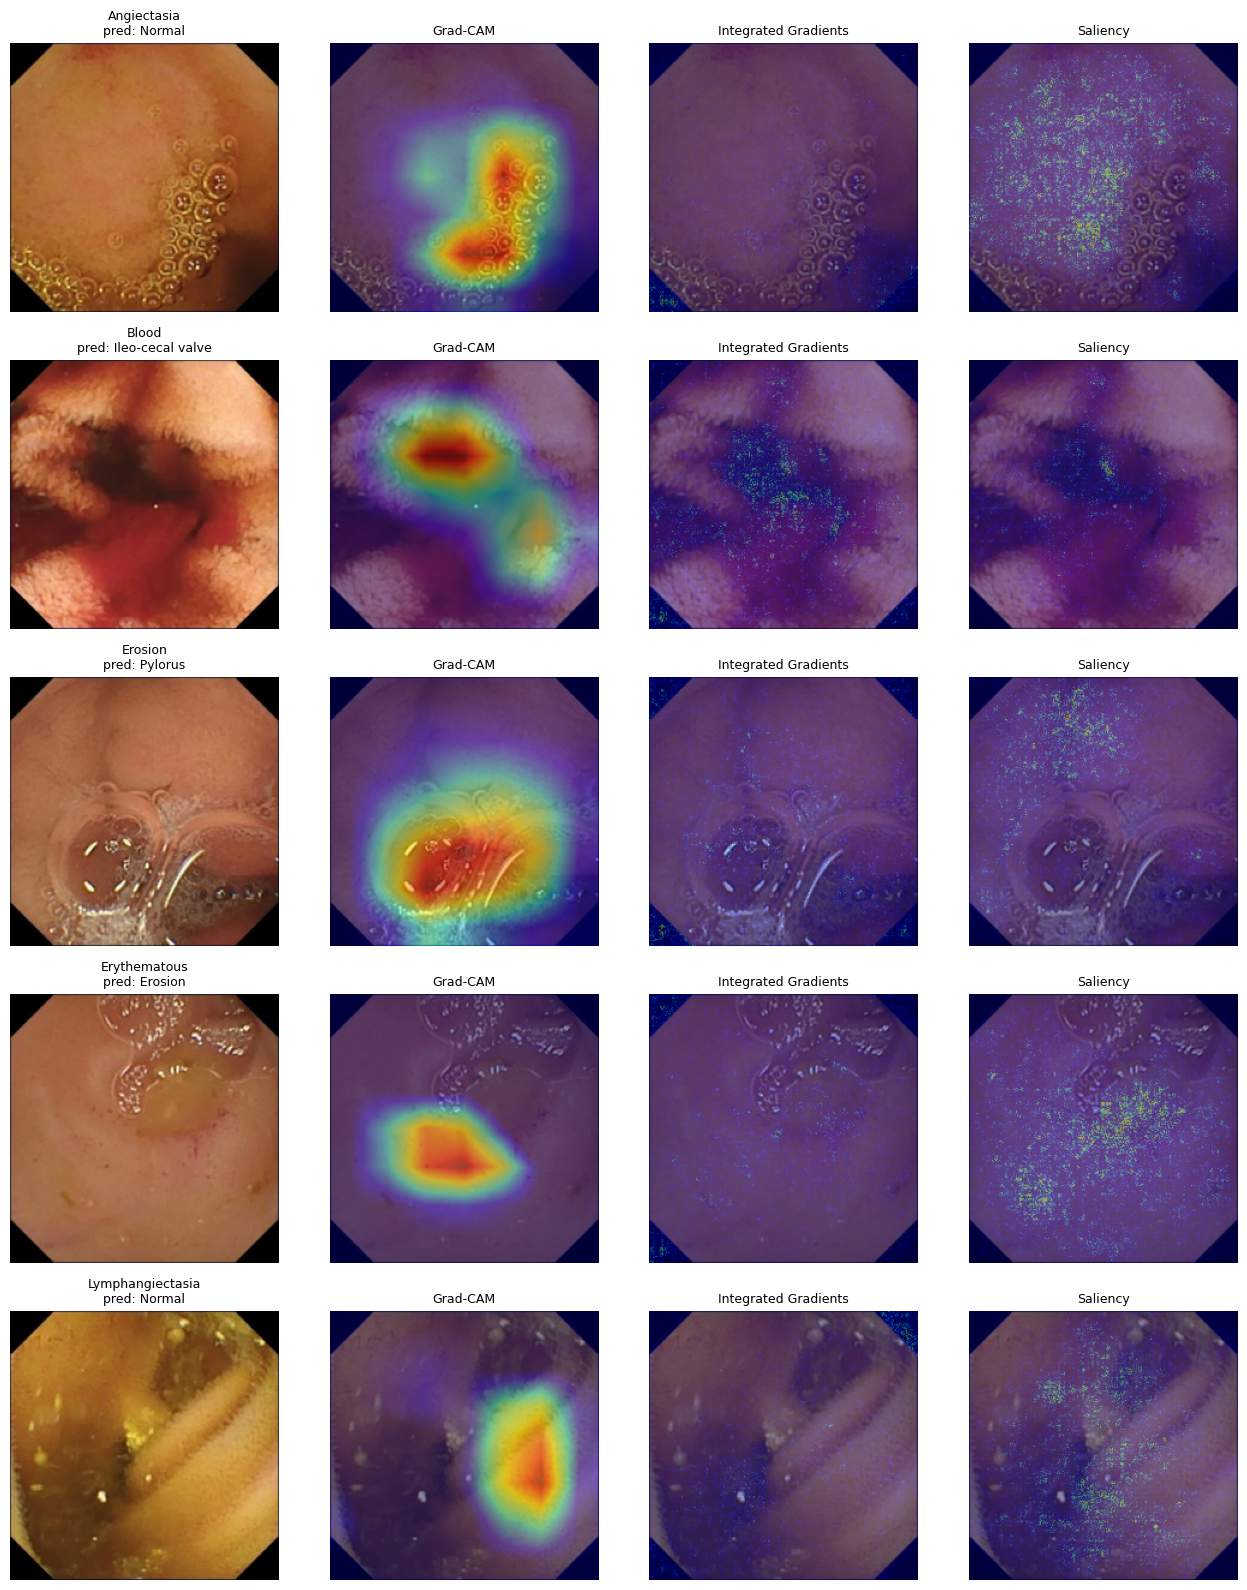

In [10]:
def to_display(x_norm):
    m, s = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
    return (x_norm.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Visual comparison on a few examples
show = explain_df.groupby("label").head(1).head(5)
fig, axes = plt.subplots(len(show), 4, figsize=(13, 3.2 * len(show)), squeeze=False)
for r, (_, row) in enumerate(show.iterrows()):
    x = eval_tf(Image.open(row["path"]).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(x).argmax(1).item()
    axes[r, 0].imshow(to_display(x[0])); axes[r, 0].set_title(f"{row['label']}\npred: {CLASSES[pred]}", fontsize=9)
    for c, m in enumerate(METHODS[:3], start=1):
        a = explain(m, x, pred).cpu().numpy()
        axes[r, c].imshow(to_display(x[0])); axes[r, c].imshow(a, cmap="jet", alpha=0.45); axes[r, c].set_title(m, fontsize=9)
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/explanations_examples.png", dpi=120); plt.show()

In [11]:
STEPS = 20   # number of deletion / insertion steps

@torch.no_grad()
def deletion_insertion(x, attr, target):
    """Returns (deletion_curve, insertion_curve) of the target-class probability."""
    blurred = TF.gaussian_blur(x, kernel_size=51, sigma=20)
    order = attr.flatten().argsort(descending=True)
    n = order.numel(); H, W = attr.shape
    del_imgs, ins_imgs = [], []
    for k in np.linspace(0, n, STEPS + 1).astype(int):
        mask = torch.zeros(n, device=x.device); mask[order[:k]] = 1; mask = mask.view(1, 1, H, W)
        del_imgs.append(x * (1 - mask) + blurred * mask)      # important pixels blurred away
        ins_imgs.append(blurred * (1 - mask) + x * mask)      # important pixels restored
    probs = lambda imgs: F.softmax(model(torch.cat(imgs)), 1)[:, target].cpu().numpy()
    return probs(del_imgs), probs(ins_imgs)

_trapz = getattr(np, "trapezoid", None) or np.trapz
auc = lambda curve: _trapz(curve, dx=1 / STEPS)
rows, curves = [], {m: {"del": [], "ins": []} for m in METHODS}
for _, row in explain_df.iterrows():
    x = eval_tf(Image.open(row["path"]).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(x).argmax(1).item()
    for m in METHODS:
        d, i = deletion_insertion(x, explain(m, x, pred), pred)
        curves[m]["del"].append(d); curves[m]["ins"].append(i)
        rows.append({"label": row["label"], "correct": CLASSES[pred] == row["label"], "method": m,
                     "deletion_auc": auc(d), "insertion_auc": auc(i)})
faith = pd.DataFrame(rows)
faith.to_csv(f"{RESULTS_DIR}/faithfulness.csv", index=False)

summary = faith.groupby("method")[["deletion_auc", "insertion_auc"]].agg(["mean", "std"]).round(3)
summary

deletion_auc        insertion_auc       
                             mean    std          mean    std
method                                                       
Grad-CAM                    0.279  0.290         0.607  0.234
Integrated Gradients        0.329  0.259         0.463  0.264
Random                      0.360  0.269         0.361  0.270
Saliency                    0.334  0.271         0.449  0.226

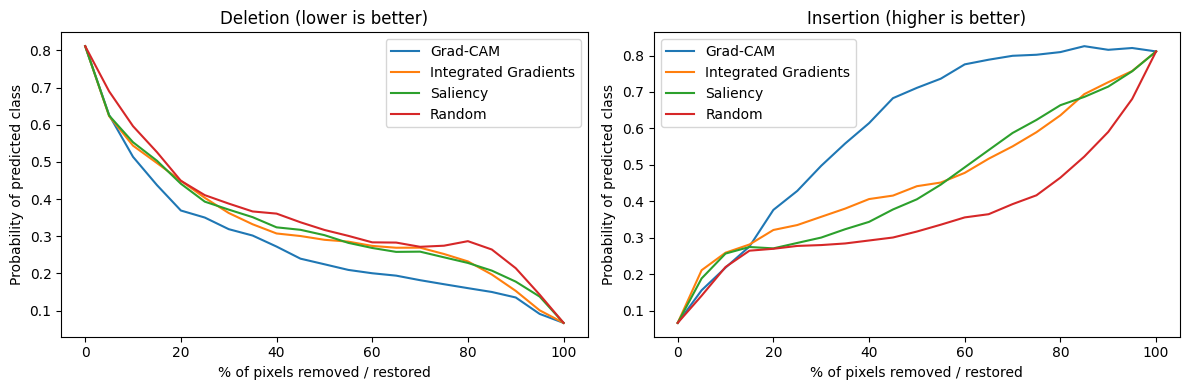

method,Grad-CAM,Integrated Gradients,Random,Saliency
label,,,,
Angiectasia,0.264,0.386,0.470,0.401
Blood,0.211,0.318,0.265,0.275
Erosion,0.537,0.572,0.629,0.607
Erythematous,0.081,0.174,0.326,0.188
Lymphangiectasia,0.297,0.307,0.289,0.333
Ulcer,0.249,0.189,0.174,0.173


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(0, 100, STEPS + 1)
for m in METHODS:
    axes[0].plot(xs, np.mean(curves[m]["del"], 0), label=m)
    axes[1].plot(xs, np.mean(curves[m]["ins"], 0), label=m)
axes[0].set_title("Deletion (lower is better)"); axes[1].set_title("Insertion (higher is better)")
for ax in axes:
    ax.set_xlabel("% of pixels removed / restored"); ax.set_ylabel("Probability of predicted class"); ax.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/faithfulness_curves.png", dpi=120); plt.show()

# Per finding: which method is most faithful?
faith.pivot_table(index="label", columns="method", values="deletion_auc", aggfunc="mean").round(3)

## 4. Calibration and uncertainty

A model is **calibrated** when its confidence matches its accuracy (predictions made with 80%
confidence should be right ~80% of the time). We measure the **Expected Calibration Error (ECE)**,
fix it with **temperature scaling** (one parameter fitted on the validation set), and use
**MC dropout** to estimate uncertainty: if the model is unsure, it should be flagged to the clinician.

Temperature = 0.77
ECE before = 0.186   ECE after = 0.231


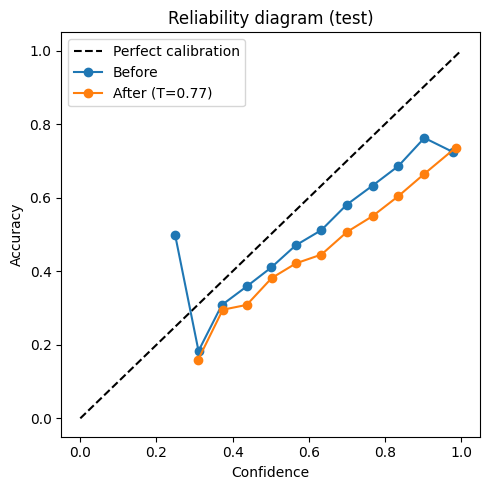

In [ ]:
def ece(probs, y, n_bins=15):
    conf, pred = probs.max(1); acc = (pred == y).float()
    bins = torch.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (conf[m].mean() - acc[m].mean()).abs()
    return e.item()

def reliability(probs, y, n_bins=15):
    conf, pred = probs.max(1); acc = (pred == y).float()
    bins = torch.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean().item()); ys.append(acc[m].mean().item())
    return xs, ys

# Temperature scaling, fitted on validation logits
val_logits, val_y = predict_logits(model, val_dl)
log_t = torch.zeros(1, requires_grad=True)
opt_t = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)
def closure():
    opt_t.zero_grad(); l = F.cross_entropy(val_logits / log_t.exp(), val_y); l.backward(); return l
opt_t.step(closure)
T_opt = log_t.exp().item()
if not 0.3 < T_opt < 10:   # safety net: a value this extreme means the fit failed (e.g. tiny validation set)
    print(f"Warning: fitted temperature {T_opt:.3f} looks wrong, falling back to T=1")
    T_opt = 1.0

p_before = F.softmax(test_logits, 1)
p_after = F.softmax(test_logits / T_opt, 1)
print(f"Temperature = {T_opt:.2f}")
print(f"ECE before = {ece(p_before, test_y):.3f}   ECE after = {ece(p_after, test_y):.3f}")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for p, name in [(p_before, "Before"), (p_after, f"After (T={T_opt:.2f})")]:
    plt.plot(*reliability(p, test_y), "o-", label=name)
plt.xlabel("Confidence"); plt.ylabel("Accuracy"); plt.title("Reliability diagram (test)"); plt.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/reliability.png", dpi=120); plt.show()

In [ ]:
# MC dropout: keep dropout active at test time, average several stochastic passes
@torch.no_grad()
def mc_dropout(loader, passes=MC_PASSES):
    model.eval()
    probs_all = []
    for x, _ in loader:
        x = x.to(device); ps = []
        feats = model.forward_features(x)
        for _ in range(passes):
            h = model.forward_head(feats, pre_logits=True)
            h = F.dropout(h, p=0.3, training=True)                # dropout before the classifier
            ps.append(F.softmax(model.get_classifier()(h).float() / T_opt, 1).cpu())
        probs_all.append(torch.stack(ps))
    return torch.cat(probs_all, 1)            # (passes, N, C)

mc = mc_dropout(test_dl)
mean_p = mc.mean(0)
entropy = -(mean_p * mean_p.clamp_min(1e-12).log()).sum(1)       # predictive uncertainty
errors = (mean_p.argmax(1) != test_y).numpy()
if 0 < errors.sum() < len(errors):
    print(f"AUROC of uncertainty for detecting errors: {roc_auc_score(errors, entropy.numpy()):.3f}")
    print("(0.5 = uncertainty says nothing, 1.0 = every error is flagged as uncertain)")

unc = pd.DataFrame({"label": [CLASSES[i] for i in test_y], "entropy": entropy.numpy(), "error": errors})
unc_by_class = unc.groupby("label").agg(mean_entropy=("entropy", "mean"), error_rate=("error", "mean"), n=("error", "size")).round(3)
unc_by_class.to_csv(f"{RESULTS_DIR}/uncertainty_by_class.csv")
unc_by_class.sort_values("mean_entropy", ascending=False)

AUROC of uncertainty for detecting errors: 0.596
(0.5 = uncertainty says nothing, 1.0 = every error is flagged as uncertain)


,mean_entropy,error_rate,n
label,,,
Erythematous,0.690,1.000,27
Angiectasia,0.524,0.958,95
Lymphangiectasia,0.454,0.957,368
Pylorus,0.429,0.372,591
Reduced Mucosal View,0.409,0.959,1787
Blood,0.386,0.998,424
Ileo-cecal valve,0.344,0.368,1394
Normal,0.303,0.217,18485
Erosion,0.261,0.907,161


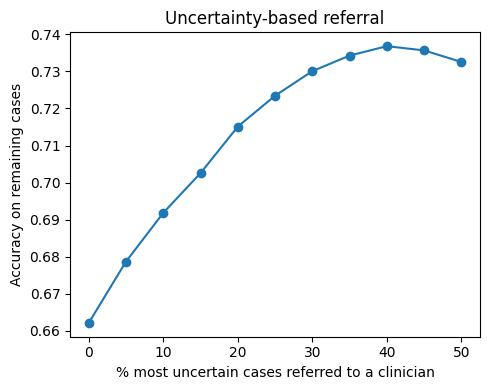

In [ ]:
# What if the model refused to answer on its most uncertain cases and sent them to a clinician?
order = np.argsort(entropy.numpy())
fractions = np.linspace(0.5, 1.0, 11)
acc_kept = [(mean_p.argmax(1).numpy()[order[: int(f * len(order))]] == test_y.numpy()[order[: int(f * len(order))]]).mean() for f in fractions]
plt.figure(figsize=(5, 4))
plt.plot(100 * (1 - fractions), acc_kept, "o-")
plt.xlabel("% most uncertain cases referred to a clinician"); plt.ylabel("Accuracy on remaining cases")
plt.title("Uncertainty-based referral"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/referral_curve.png", dpi=120); plt.show()

## 5. Colour sensitivity

Many capsule findings (blood, erythema, ulcers, angiectasia) are recognised largely by colour, and
capsule cameras differ in colour rendering. How much do **predictions** and **explanations**
change when we shift **hue** or **saturation**?

- **Prediction stability:** % of images whose predicted class stays the same.
- **Explanation stability:** correlation between the Grad-CAM map of the original image and of the
  colour-shifted image (1 = identical explanation).

In [ ]:
colour_df = sample_per_class(test_df, max(1, N_COLOUR // NUM_CLASSES))

HUE_SHIFTS = [-0.06, -0.03, 0.03, 0.06]
SAT_FACTORS = [0.5, 0.75, 1.25, 1.5]
perturbations = [("hue", h) for h in HUE_SHIFTS] + [("saturation", s) for s in SAT_FACTORS]

def perturb(raw, kind, v):
    return TF.adjust_hue(raw, v) if kind == "hue" else TF.adjust_saturation(raw, v)

rows = []
for _, row in colour_df.iterrows():
    raw = raw_tf(Image.open(row["path"]).convert("RGB"))
    x0 = normalize(raw).unsqueeze(0).to(device)
    with torch.no_grad():
        p0 = model(x0).argmax(1).item()
    cam0 = explain("Grad-CAM", x0, p0).flatten()
    for kind, v in perturbations:
        x1 = normalize(perturb(raw, kind, v)).unsqueeze(0).to(device)
        with torch.no_grad():
            p1 = model(x1).argmax(1).item()
        cam1 = explain("Grad-CAM", x1, p0).flatten()
        corr = torch.corrcoef(torch.stack([cam0, cam1]))[0, 1].item() if cam0.std() > 0 and cam1.std() > 0 else np.nan
        rows.append({"label": row["label"], "kind": kind, "value": v,
                     "prediction_unchanged": p0 == p1, "explanation_corr": corr})
colour = pd.DataFrame(rows)
colour.to_csv(f"{RESULTS_DIR}/colour_sensitivity.csv", index=False)

colour.groupby(["kind", "value"])[["prediction_unchanged", "explanation_corr"]].mean().round(3)

prediction_unchanged  explanation_corr
kind       value                                        
hue        -0.06                 0.320             0.472
           -0.03                 0.592             0.704
            0.03                 0.618             0.755
            0.06                 0.527             0.602
saturation  0.50                 0.238             0.412
            0.75                 0.447             0.579
            1.25                 0.718             0.753
            1.50                 0.504             0.557

In [ ]:
by_class = colour.groupby(["label", "kind"])["prediction_unchanged"].mean().unstack().round(3)
by_class.plot.barh(figsize=(7, 5))
plt.xlabel("Share of predictions unchanged"); plt.title("Prediction stability under colour shifts, per class")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/colour_by_class.png", dpi=120); plt.show()
by_class

In [ ]:
ex = colour_df[colour_df["label"].isin(["Blood", "Ulcer", "Erythematous", "Angiectasia"])].head(1)
if len(ex):
    row = ex.iloc[0]; raw = raw_tf(Image.open(row["path"]).convert("RGB"))
    shifts = [0.0] + HUE_SHIFTS
    fig, axes = plt.subplots(2, len(shifts), figsize=(3 * len(shifts), 6))
    for c, h in enumerate(shifts):
        img = perturb(raw, "hue", h) if h else raw
        x = normalize(img).unsqueeze(0).to(device)
        with torch.no_grad():
            p = model(x).argmax(1).item()
        cam = explain("Grad-CAM", x, p).cpu().numpy()
        axes[0, c].imshow(img.permute(1, 2, 0)); axes[0, c].set_title(f"hue {h:+.2f}\npred: {CLASSES[p]}", fontsize=9)
        axes[1, c].imshow(img.permute(1, 2, 0)); axes[1, c].imshow(cam, cmap="jet", alpha=0.45)
        for ax in axes[:, c]: ax.axis("off")
    plt.suptitle(f"True class: {row['label']}"); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/colour_example.png", dpi=120); plt.show()

## 6. Summary

Write your observations here after the run (they go into the README):
- Baseline: balanced accuracy / macro-F1, hardest classes and why.
- Faithfulness: which explanation method beats random most clearly? Does it change per finding?
- Calibration: ECE before/after temperature scaling; are rare classes more uncertain?
  How much does accuracy improve when referring the most uncertain cases?
- Colour: which findings are most colour-dependent? Do explanations stay stable when predictions do?
- Limits and next steps (e.g. evaluating the explanations with gastroenterologists).

In [ ]:
results = {
    "model": MODEL_NAME, "epochs": EPOCHS,
    "test_balanced_accuracy": round(float(bacc), 4), "test_macro_f1": round(float(mf1), 4),
    "temperature": round(T_opt, 3),
    "ece_before": round(ece(p_before, test_y), 4), "ece_after": round(ece(p_after, test_y), 4),
    "faithfulness": faith.groupby("method")[["deletion_auc", "insertion_auc"]].mean().round(4).to_dict(),
    "colour_prediction_unchanged": colour.groupby("kind")["prediction_unchanged"].mean().round(4).to_dict(),
}
with open(f"{RESULTS_DIR}/results.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))